Freeform GPT Features — EDA + XGBoost

1. Load & inspect freeform feature CSV
2. Sanity checks vs RDKit ground truth (side-by-side grid)
3. Cross-correlation heatmap: RDKit vs freeform GPT
4. Build feature matrix
5. XGBoost — exact same pipeline as `build_train.py`

**Only change the config cell when switching models.**

In [1]:
from IPython.display import display
import warnings, random
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    f1_score, precision_score, recall_score, accuracy_score, matthews_corrcoef
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import xgboost as xgb

def find_data_dir():
    here = Path().resolve()
    for candidate in [here / "data", here.parent / "data"]:
        if (candidate / "prestwick_library_screened.tsv.gz").exists():
            return candidate
    raise FileNotFoundError(f"Cannot find data/ from {here}")

DATA_DIR   = find_data_dir()
RDKIT_PATH = DATA_DIR / "maier_chemdesc_representation.tsv"
PAIRS_FILE = DATA_DIR / "results" / "mole_plus_gpt41mini" / "compound_strain_pairs_with_features_mole_plus_gpt.csv"

# ── Change these two lines to switch models ────────────────────────────────────
FREEFORM_CSV = DATA_DIR / "gpt_generation_without_guidance" / "gpt_features4omini_gpt-4o-mini_freeform.csv"
MODEL_TAG    = "gpt-4o-mini-freeform"

OUT_DIR = DATA_DIR / "feature_matrix_gpt" / "freeform" / MODEL_TAG
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Freeform CSV : {FREEFORM_CSV}")
print(f"Output dir   : {OUT_DIR}")

Freeform CSV : D:\Hiwi\GPT+Mole\GPT+Mole\data\gpt_generation_without_guidance\gpt_features4omini_gpt-4o-mini_freeform.csv
Output dir   : D:\Hiwi\GPT+Mole\GPT+Mole\data\feature_matrix_gpt\freeform\gpt-4o-mini-freeform


## 1. Load & Inspect

In [2]:
raw = pd.read_csv(FREEFORM_CSV)
META_COLS    = {"prestwick_ID", "smiles_resolution", "input"}
feature_cols = [c for c in raw.columns if c not in META_COLS]

print(f"Shape        : {raw.shape}")
print(f"Feature cols : {feature_cols}")
raw.head(3)

Shape        : (1197, 41)
Feature cols : ['molecular_weight', 'num_atoms', 'num_bonds', 'num_rings', 'num_hydrogen_bond_donors', 'num_hydrogen_bond_acceptors', 'num_rotatable_bonds', 'num_aromatic_rings', 'num_heteroatoms', 'num_nitrogens', 'num_oxygens', 'num_carbon_atoms', 'num_sulfur_atoms', 'num_fluorine_atoms', 'num_chlorine_atoms', 'num_bromine_atoms', 'num_iodine_atoms', 'log_p', 'polar_surface_area', 'topological_polar_surface_area', 'molar_refractivity', 'lipinski_rule_of_five_violations', 'synthetic_accessibility_score', 'pka', 'solubility', 'bioavailability_score', 'antimicrobial_activity_score', 'bacterial_resistance_score', 'toxicity_score', 'metabolic_stability_score', 'binding_affinity_estimate', 'target_selectivity_score', 'cell_membrane_permeability', 'efflux_pump_substrate_score', 'inhibition_constant_estimate', 'antibiotic_class', 'mechanism_of_action', 'spectrum_of_activity']


,molecular_weight,num_atoms,num_bonds,num_rings,num_hydrogen_bond_donors,num_hydrogen_bond_acceptors,num_rotatable_bonds,num_aromatic_rings,num_heteroatoms,num_nitrogens,...,target_selectivity_score,cell_membrane_permeability,efflux_pump_substrate_score,inhibition_constant_estimate,antibiotic_class,mechanism_of_action,spectrum_of_activity,input,prestwick_ID,smiles_resolution
0,158.14,10,9,2,3,4,0,2,5,4,...,0.6,0.5,0.2,0.1,1,1,2,"{'query_smiles': 'Nc1nc2n[nH]nc2c(=O)[nH]1', '...",Prestw-1,fast
1,201.25,14,15,1,3,5,1,1,5,3,...,0.9,0.5,0.3,20.0,1,2,3,{'query_smiles': 'NC(N)=NS(=O)(=O)c1ccc(N)cc1'...,Prestw-10,fast
2,305.32,24,25,4,3,5,3,3,5,3,...,0.9,0.6,0.1,5.0,1,2,3,{'query_smiles': 'COC(=O)Nc1nc2ccc(C(=O)c3cccs...,Prestw-100,fast


In [3]:
print(pd.DataFrame({"dtype": raw[feature_cols].dtypes,
                     "nulls": raw[feature_cols].isnull().sum()}))
raw[feature_cols].describe().round(3)

                                    dtype  nulls
molecular_weight                  float64      0
num_atoms                           int64      0
num_bonds                           int64      0
num_rings                           int64      0
num_hydrogen_bond_donors            int64      0
num_hydrogen_bond_acceptors         int64      0
num_rotatable_bonds                 int64      0
num_aromatic_rings                  int64      0
num_heteroatoms                     int64      0
num_nitrogens                       int64      0
num_oxygens                         int64      0
num_carbon_atoms                    int64      0
num_sulfur_atoms                    int64      0
num_fluorine_atoms                  int64      0
num_chlorine_atoms                  int64      0
num_bromine_atoms                   int64      0
num_iodine_atoms                    int64      0
log_p                             float64      0
polar_surface_area                float64      0
topological_polar_su

,molecular_weight,num_atoms,num_bonds,num_rings,num_hydrogen_bond_donors,num_hydrogen_bond_acceptors,num_rotatable_bonds,num_aromatic_rings,num_heteroatoms,num_nitrogens,...,toxicity_score,metabolic_stability_score,binding_affinity_estimate,target_selectivity_score,cell_membrane_permeability,efflux_pump_substrate_score,inhibition_constant_estimate,antibiotic_class,mechanism_of_action,spectrum_of_activity
count,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,...,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000
mean,292.864,25.054,25.084,2.657,2.871,4.540,5.007,1.555,3.800,1.969,...,0.312,0.903,19.152,1.168,0.838,0.289,10.868,0.969,1.699,2.554
std,100.372,12.716,12.905,1.419,1.953,2.494,2.276,0.975,1.974,1.432,...,0.482,0.882,28.660,1.244,0.860,0.384,10.748,0.173,0.519,0.810
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,-9.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,223.290,18.000,17.000,2.000,2.000,3.000,4.000,1.000,2.000,1.000,...,0.100,0.600,5.000,0.900,0.500,0.100,5.000,1.000,1.000,2.000
50%,305.090,24.000,23.000,3.000,3.000,4.000,5.000,2.000,4.000,2.000,...,0.200,0.700,7.000,0.900,0.600,0.300,10.000,1.000,2.000,3.000
75%,336.390,30.000,29.000,3.000,4.000,6.000,6.000,2.000,5.000,3.000,...,0.300,0.800,50.000,0.900,0.800,0.300,10.000,1.000,2.000,3.000
max,1025.250,132.000,131.000,10.000,12.000,22.000,15.000,5.000,20.000,10.000,...,3.000,6.000,100.000,7.000,5.000,3.000,50.000,1.000,2.000,3.000


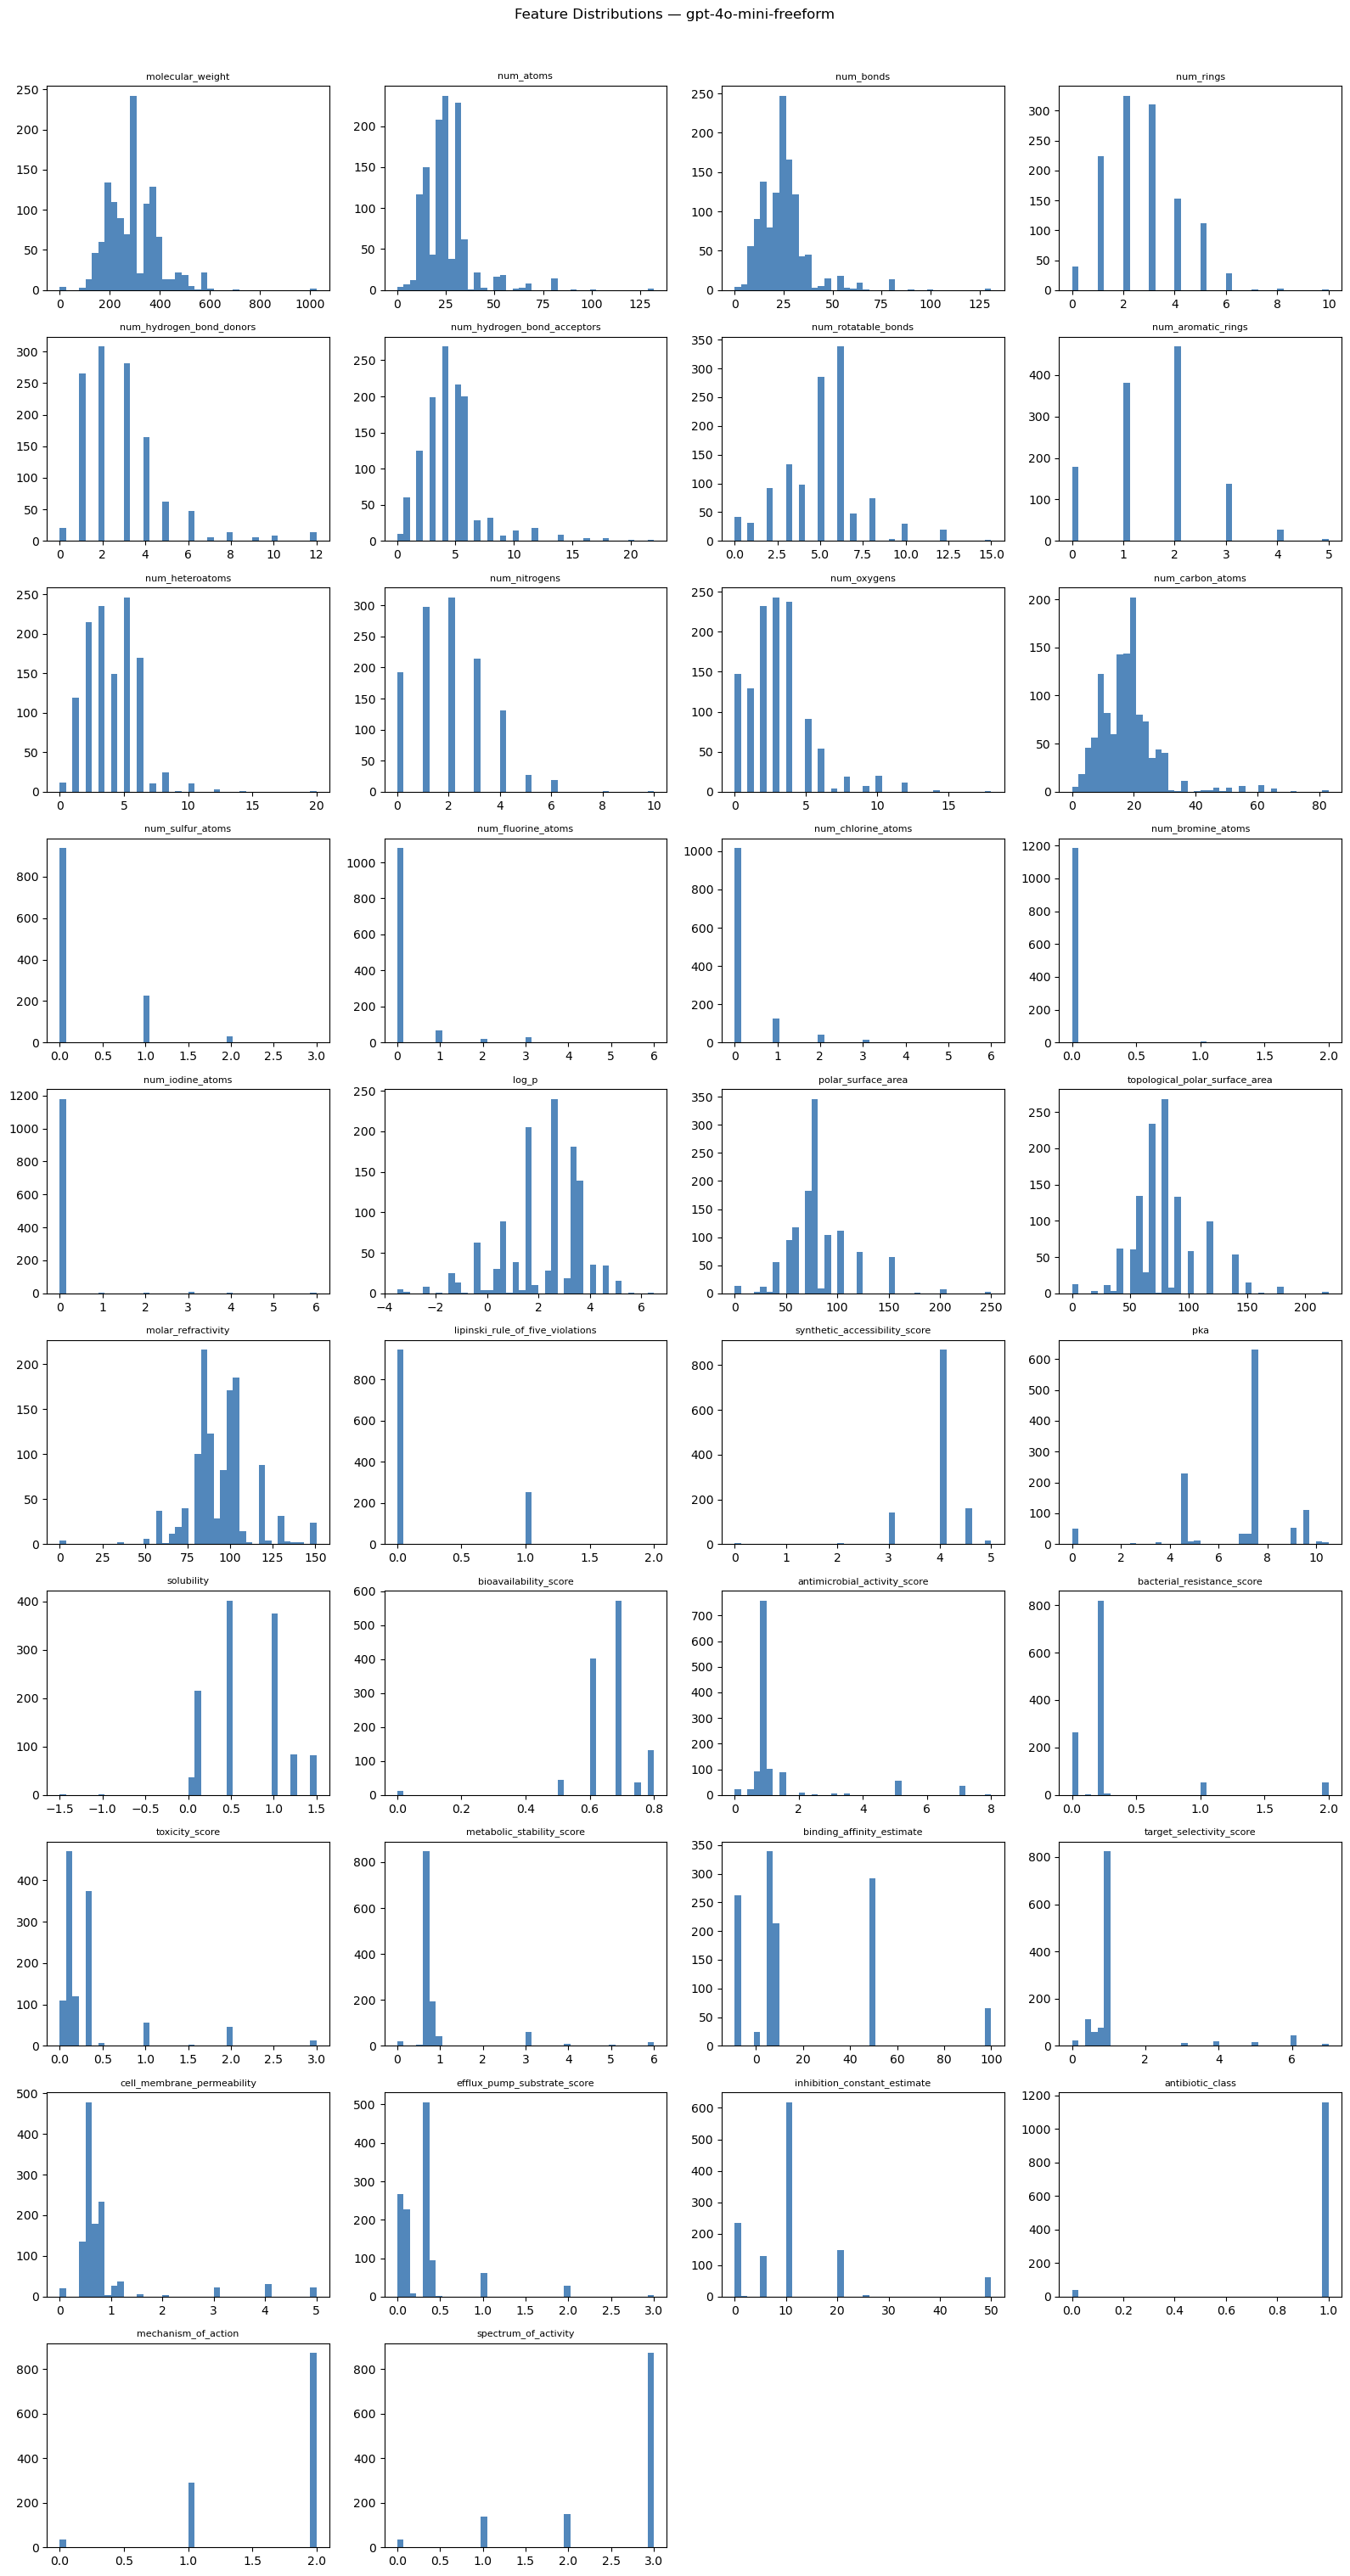

In [4]:
n, ncols = len(feature_cols), 4
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    axes[i].hist(raw[col].dropna(), bins=40, color="#185FA5", alpha=0.75, edgecolor="none")
    axes[i].set_title(col, fontsize=8)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
fig.suptitle(f"Feature Distributions — {MODEL_TAG}", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Sanity Checks vs RDKit (Side-by-Side)

In [5]:
rdkit = pd.read_csv(RDKIT_PATH, sep="\t")

# GPT feature name -> closest RDKit column
SANITY_MAP = {
    "molecular_weight":               "MolWt",
    "num_hydrogen_bond_donors":       "NumHDonors",
    "num_hydrogen_bond_acceptors":    "NumHAcceptors",
    "num_aromatic_rings":             "NumAromaticRings",
    "num_rings":                      "NumRings",
    "topological_polar_surface_area": "TPSA",
    "fraction_csp3":                  "FractionCSP3",
    "num_rotatable_bonds":            "NumRotatableBonds",
}

valid_pairs = [(g, r) for g, r in SANITY_MAP.items()
               if g in raw.columns and r in rdkit.columns]
print(f"Sanity check pairs: {len(valid_pairs)}")
for g, r in valid_pairs:
    print(f"  {g:42s} -> {r}")

Sanity check pairs: 7
  molecular_weight                           -> MolWt
  num_hydrogen_bond_donors                   -> NumHDonors
  num_hydrogen_bond_acceptors                -> NumHAcceptors
  num_aromatic_rings                         -> NumAromaticRings
  num_rings                                  -> NumRings
  topological_polar_surface_area             -> TPSA
  num_rotatable_bonds                        -> NumRotatableBonds


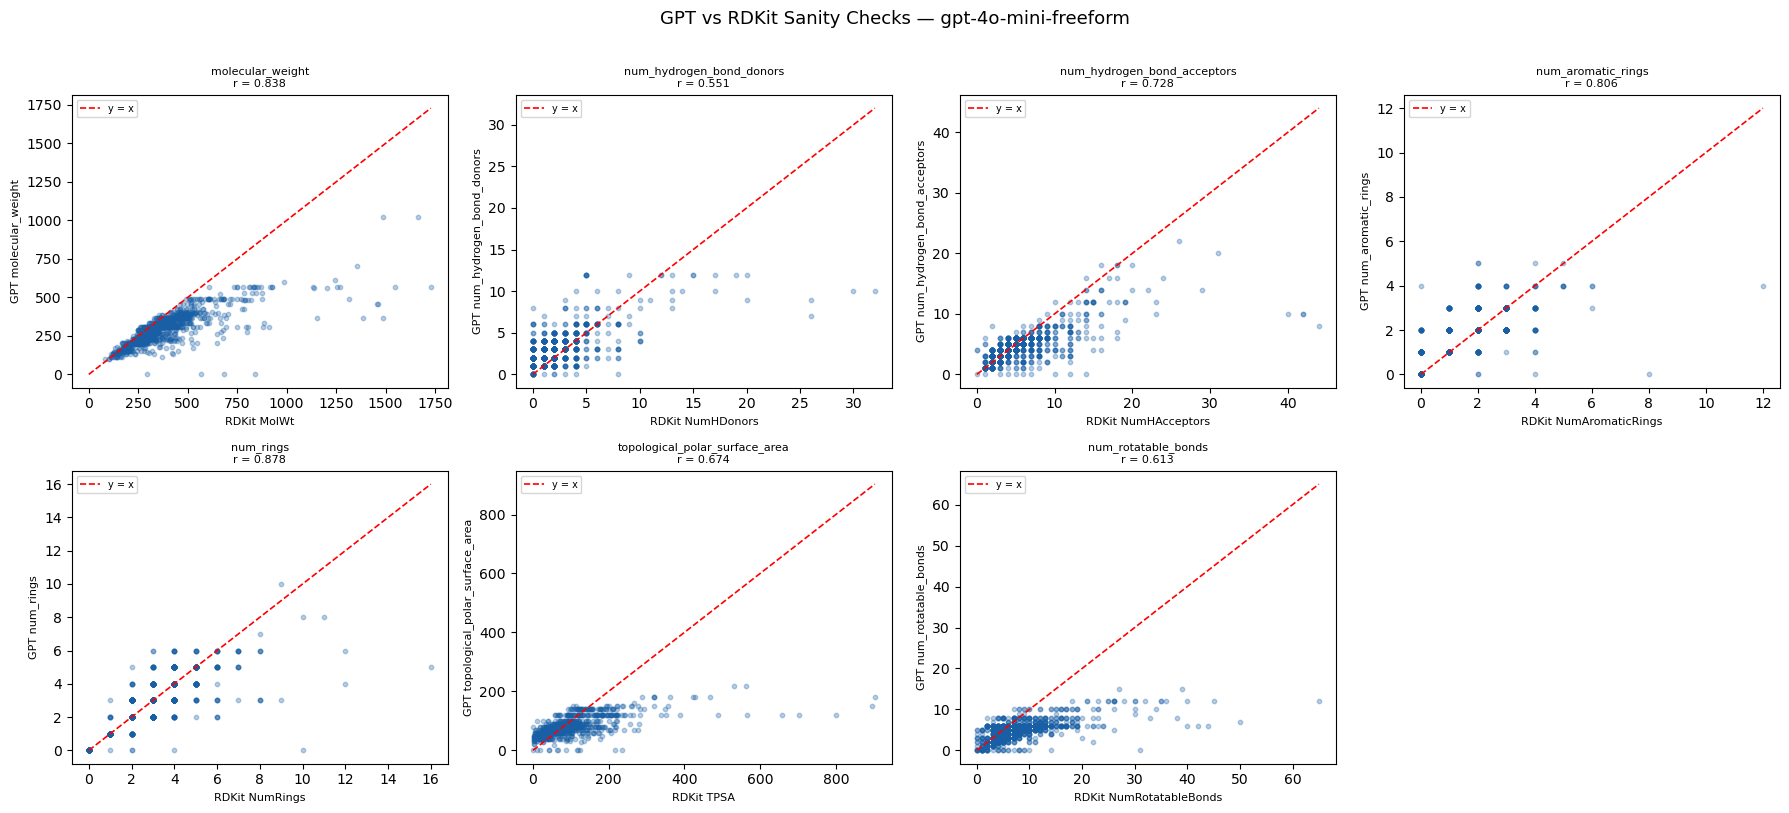

5 MOST SIMILAR (GPT ≈ RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-1080,265.338,265.34,0.0
1,Prestw-1207,180.159,180.16,0.0
2,Prestw-17,197.190,197.19,-0.0
3,Prestw-411,290.447,290.45,0.0
4,Prestw-440,290.447,290.45,0.0



5 MOST OVERESTIMATED (GPT >> RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-192,258.233,305.27,47.04
1,Prestw-1203,130.078,174.06,43.98
2,Prestw-1362,264.325,307.43,43.11
3,Prestw-35,248.307,290.34,42.03
4,Prestw-762,249.295,290.34,41.04



5 MOST UNDERESTIMATED (GPT << RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-919,1728.990,570.73,-1158.26
1,Prestw-160,1488.807,365.45,-1123.36
2,Prestw-506,1385.461,365.45,-1020.01
3,Prestw-159,1461.429,455.50,-1005.93
4,Prestw-321,1457.397,455.50,-1001.90


In [6]:
merged = raw[["prestwick_ID"] + [g for g, _ in valid_pairs]].merge(
    rdkit[["prestwick_ID"] + [r for _, r in valid_pairs]], on="prestwick_ID", how="inner"
)

n_pairs = len(valid_pairs)
ncols   = min(4, n_pairs)
nrows   = (n_pairs + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.5, nrows * 4))
axes = np.array(axes).flatten()

sanity_results = []
for i, (gpt_col, rdkit_col) in enumerate(valid_pairs):
    ax   = axes[i]
    x, y = merged[rdkit_col], merged[gpt_col]
    r, p  = spearmanr(x, y)
    sanity_results.append({"gpt": gpt_col, "rdkit": rdkit_col,
                            "spearman_r": round(r, 4), "p": round(p, 6)})
    ax.scatter(x, y, alpha=0.3, s=10, color="#185FA5", rasterized=True)
    mn, mx = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([mn, mx], [mn, mx], "r--", lw=1.2, label="y = x")
    ax.set_xlabel(f"RDKit {rdkit_col}", fontsize=8)
    ax.set_ylabel(f"GPT {gpt_col}", fontsize=8)
    ax.set_title(f"{gpt_col}\nr = {r:.3f}", fontsize=8)
    ax.legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f"GPT vs RDKit Sanity Checks — {MODEL_TAG}", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "sanity_checks.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Molecular weight deep-dive table ──────────────────────────────────────────
mw_gpt_col   = "molecular_weight"
mw_rdkit_col = "MolWt"

if mw_gpt_col in merged.columns and mw_rdkit_col in merged.columns:
    mw = merged[["prestwick_ID", mw_rdkit_col, mw_gpt_col]].copy()
    mw = mw.rename(columns={mw_rdkit_col: "rdkit_MolWt", mw_gpt_col: "gpt_MolWt"})
    mw["diff"]     = (mw["gpt_MolWt"] - mw["rdkit_MolWt"]).round(2)
    mw["abs_diff"] = mw["diff"].abs()

    closest   = mw.nsmallest(5, "abs_diff").reset_index(drop=True)
    overest   = mw.nlargest(5,  "diff").reset_index(drop=True)
    underest  = mw.nsmallest(5, "diff").reset_index(drop=True)

    print("5 MOST SIMILAR (GPT ≈ RDKit):")
    display(closest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST OVERESTIMATED (GPT >> RDKit):")
    display(overest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST UNDERESTIMATED (GPT << RDKit):")
    display(underest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

## 3. Cross-Correlation: RDKit vs Freeform GPT

RDKit: 96 features  |  GPT freeform: 38 features


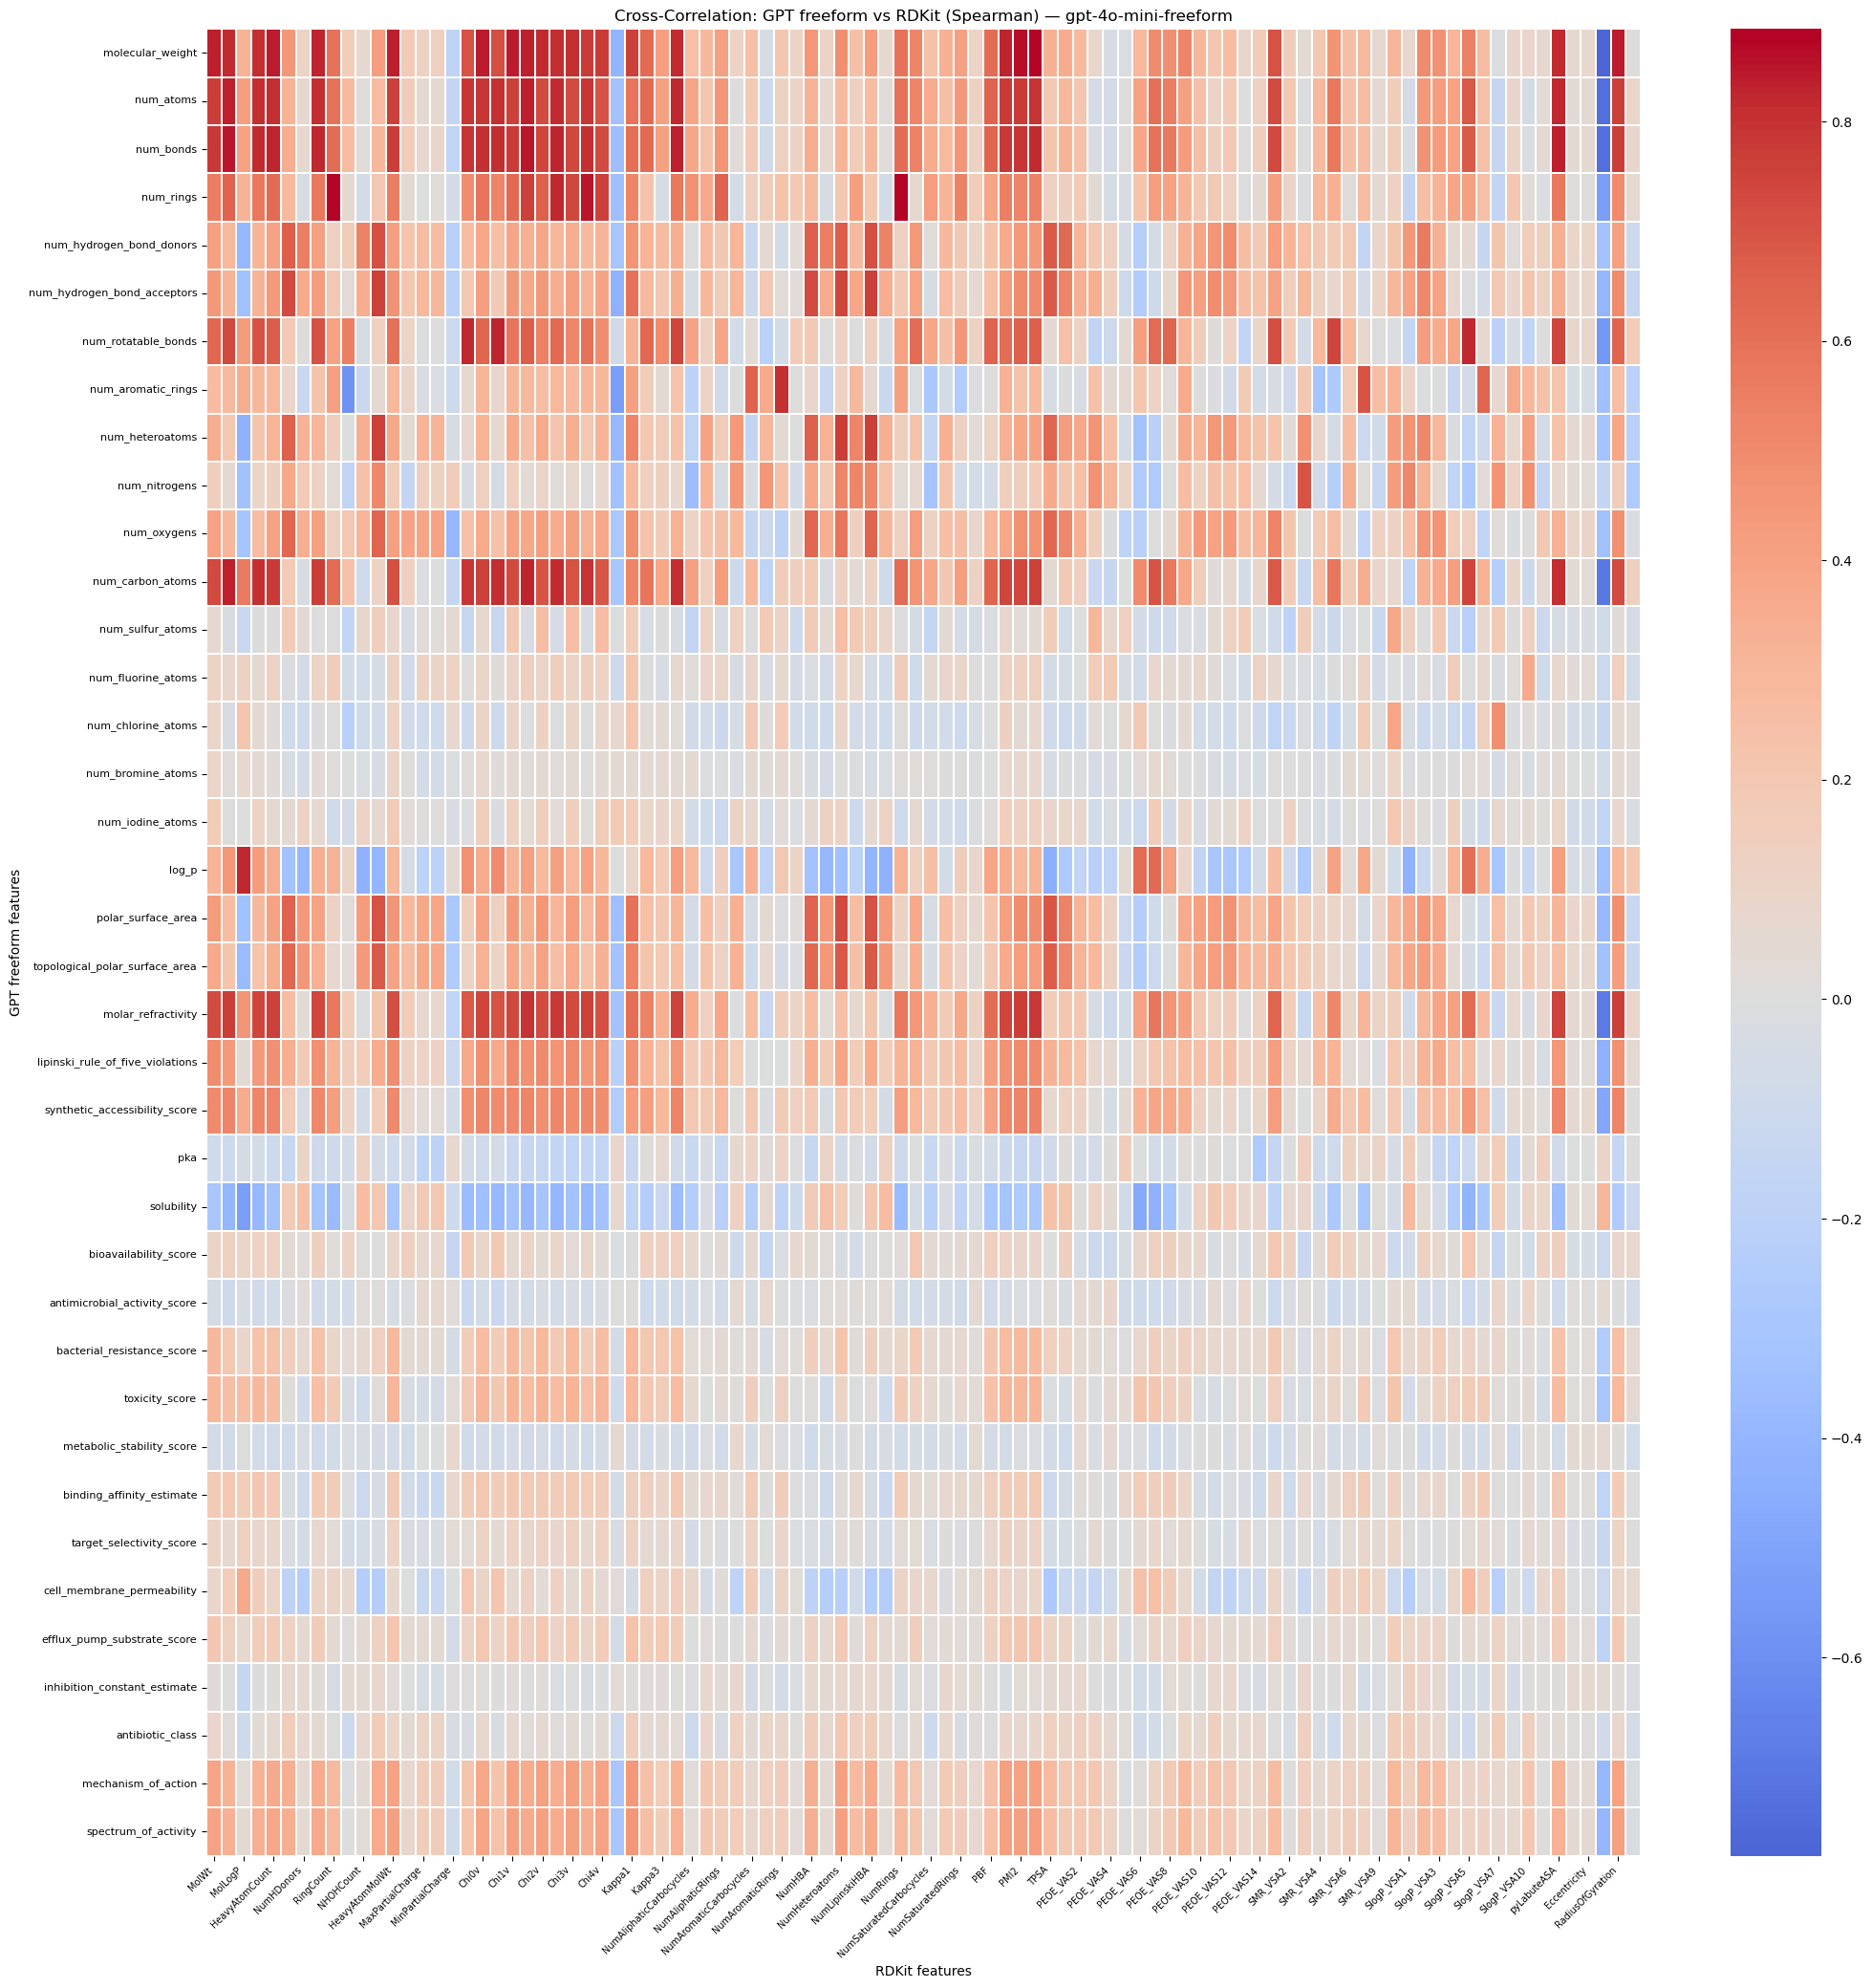

In [7]:
rdkit_al = (rdkit.set_index("prestwick_ID")
                .apply(pd.to_numeric, errors="coerce").fillna(0))
rdkit_al = rdkit_al.loc[:, rdkit_al.std() > 1e-6]

gpt_al = (raw.set_index("prestwick_ID")[feature_cols]
             .apply(pd.to_numeric, errors="coerce").fillna(0))
gpt_al = gpt_al.loc[:, gpt_al.std() > 1e-6]

common   = rdkit_al.index.intersection(gpt_al.index)
rdkit_al = rdkit_al.loc[common].sort_index()
gpt_al   = gpt_al.loc[common].sort_index()

rdkit_al.columns = ["rdkit__" + c for c in rdkit_al.columns]
gpt_al.columns   = ["gpt__"   + c for c in gpt_al.columns]

n_rdkit, n_gpt = rdkit_al.shape[1], gpt_al.shape[1]
print(f"RDKit: {n_rdkit} features  |  GPT freeform: {n_gpt} features")

# Compute only the GPT × RDKit cross-correlation block
combined_all = pd.concat([rdkit_al, gpt_al], axis=1)
full_corr    = combined_all.corr(method="spearman")
corr_sp      = full_corr   # keep for novelty cell downstream

rdkit_cols_idx = [c for c in full_corr.columns if c.startswith("rdkit__")]
gpt_cols_idx   = [c for c in full_corr.columns if c.startswith("gpt__")]
cross_block    = full_corr.loc[gpt_cols_idx, rdkit_cols_idx]

# Clean axis labels (remove prefixes)
cross_block.index   = [c.replace("gpt__", "")   for c in cross_block.index]
cross_block.columns = [c.replace("rdkit__", "") for c in cross_block.columns]

fig, ax = plt.subplots(figsize=(max(20, n_rdkit * 0.22), max(4, n_gpt * 0.55)))
sns.heatmap(cross_block, cmap="coolwarm", center=0, annot=(n_gpt <= 30),
            fmt=".2f", linewidths=0.3, rasterized=True, ax=ax)
ax.set_title(f"Cross-Correlation: GPT freeform vs RDKit (Spearman) — {MODEL_TAG}", fontsize=12)
ax.set_xlabel("RDKit features", fontsize=10)
ax.set_ylabel("GPT freeform features", fontsize=10)
plt.xticks(rotation=45, ha="right", fontsize=7)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "cross_corr_gpt_vs_rdkit.png", dpi=150, bbox_inches="tight")
plt.show()

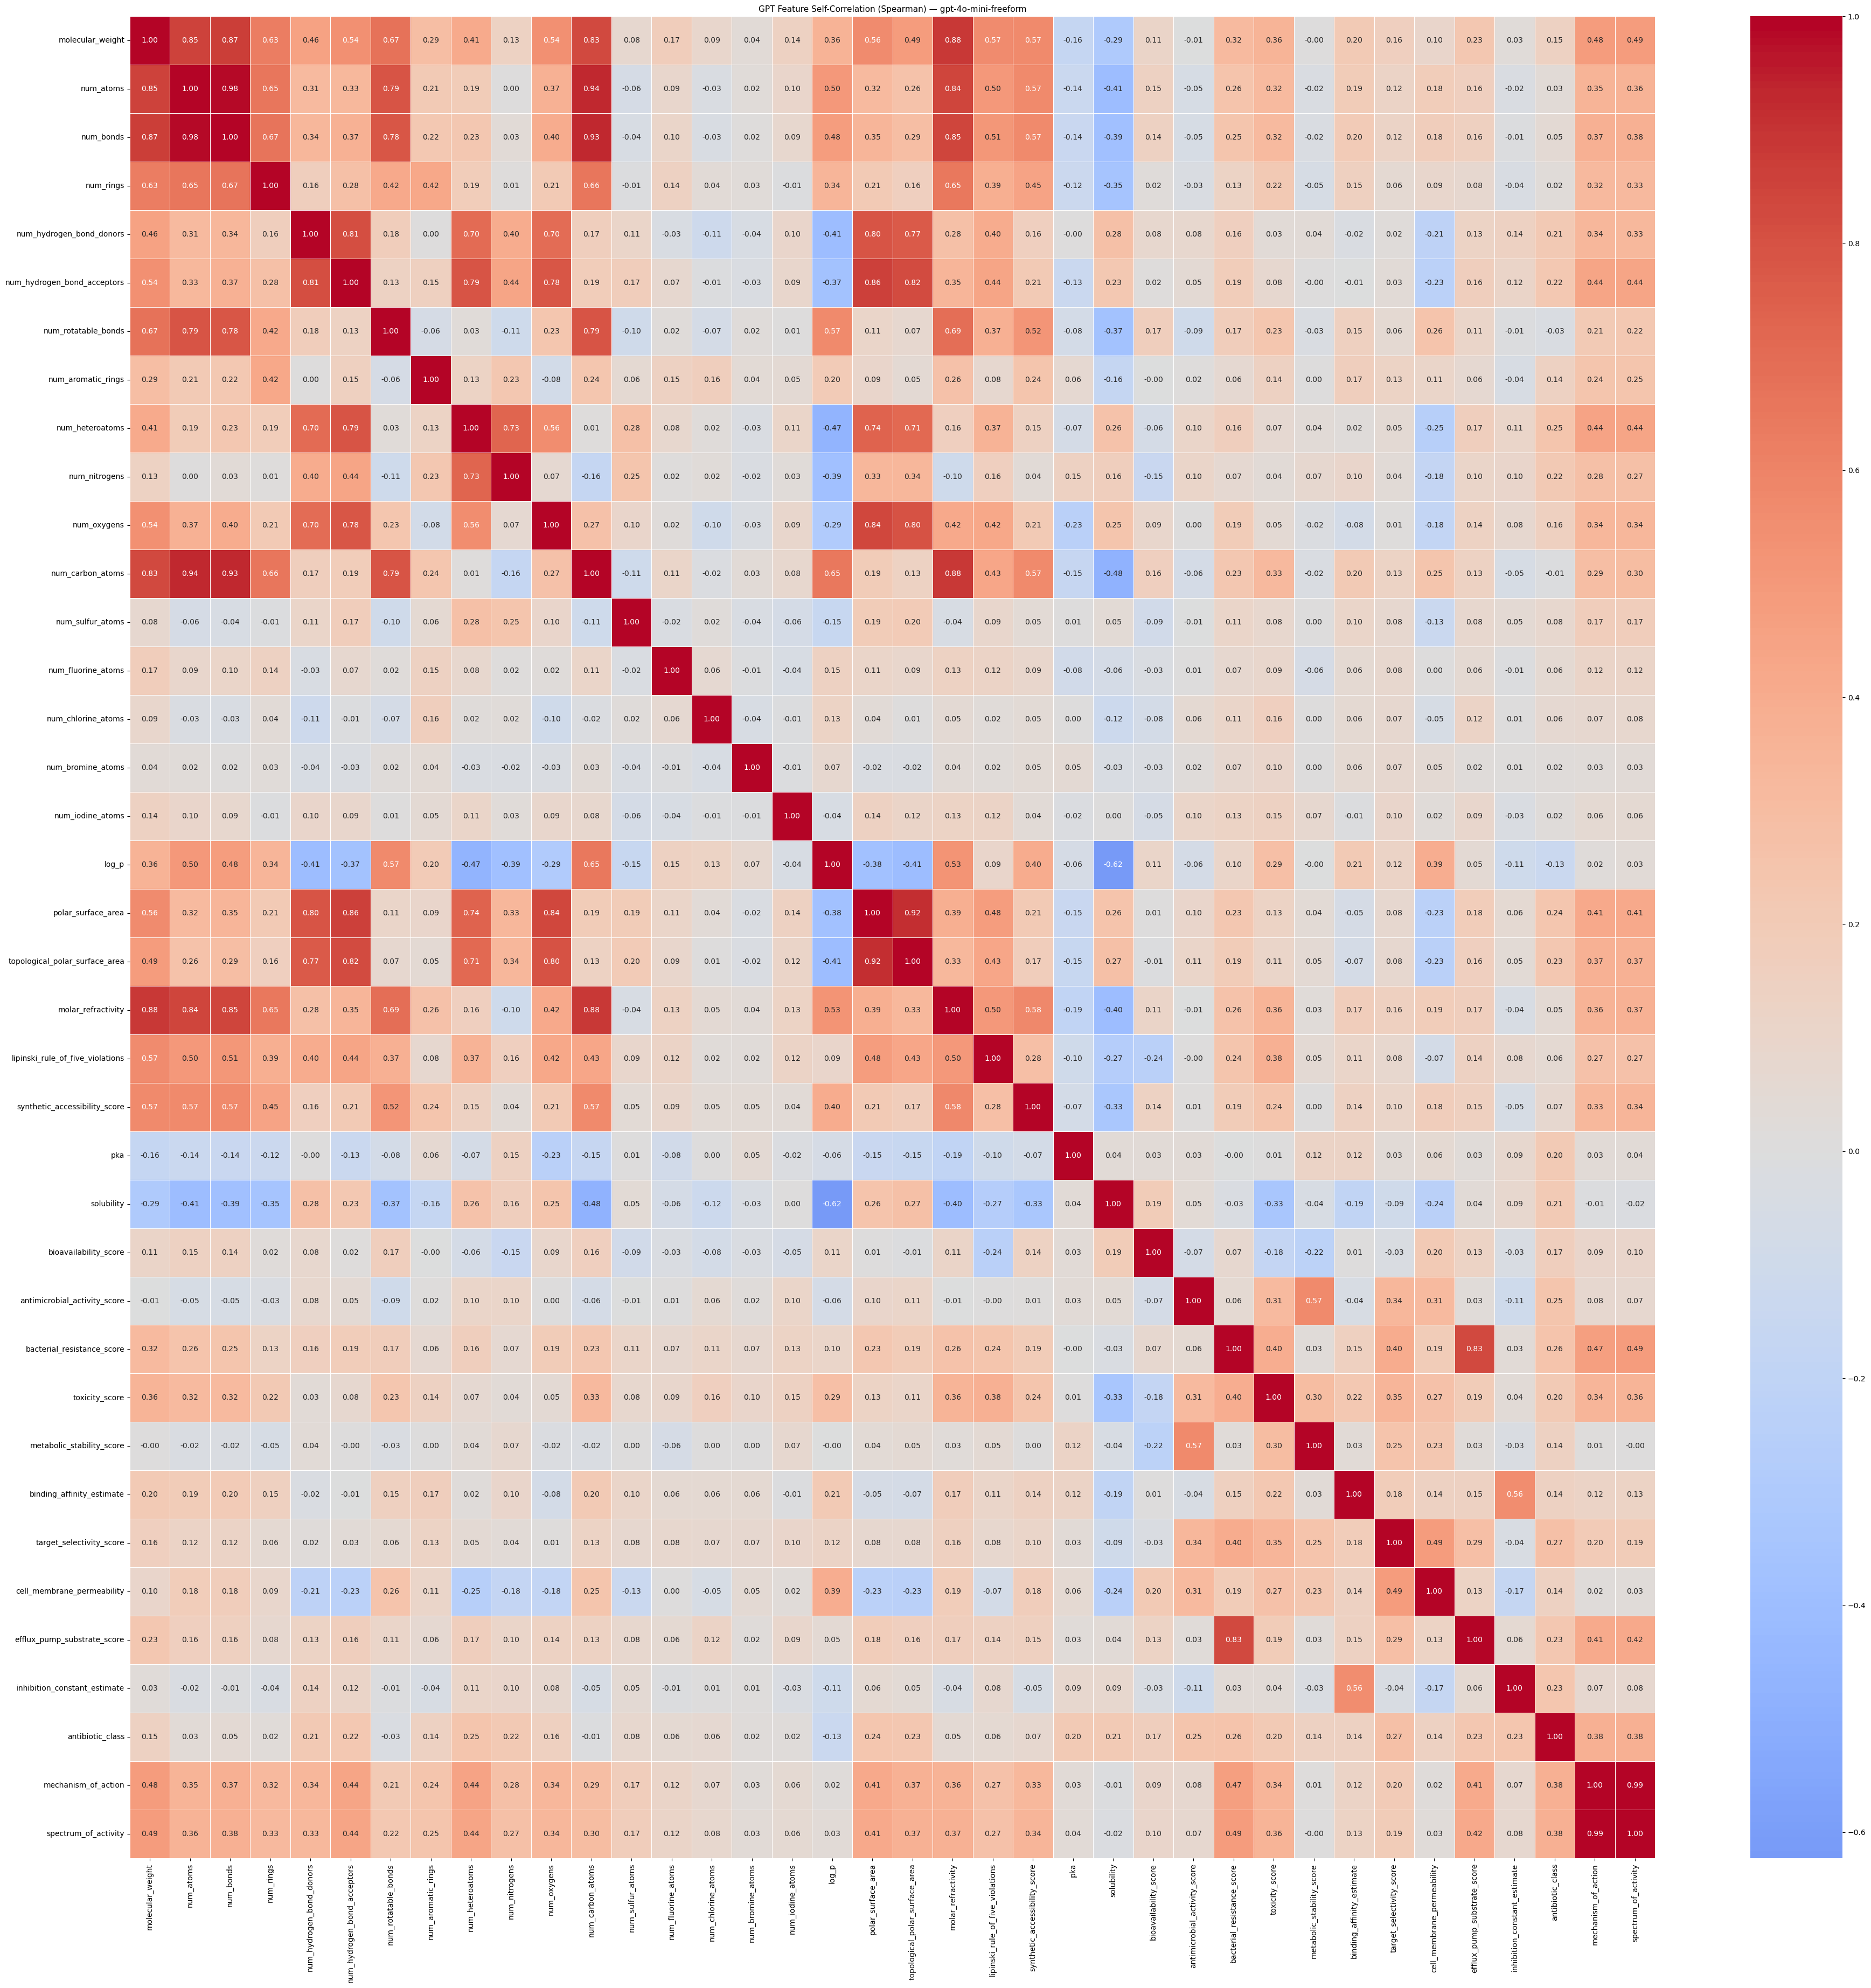

In [8]:
corr_self  = gpt_al.corr(method="spearman")
gpt_labels = [c.replace("gpt__", "") for c in gpt_al.columns]

fig, ax = plt.subplots(figsize=(max(8, n_gpt), max(7, n_gpt - 1)))
sns.heatmap(corr_self, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            xticklabels=gpt_labels, yticklabels=gpt_labels, linewidths=0.4, ax=ax)
ax.set_title(f"GPT Feature Self-Correlation (Spearman) — {MODEL_TAG}", fontsize=11)
plt.tight_layout()
plt.savefig(OUT_DIR / "self_corr.png", dpi=150, bbox_inches="tight")
plt.show()

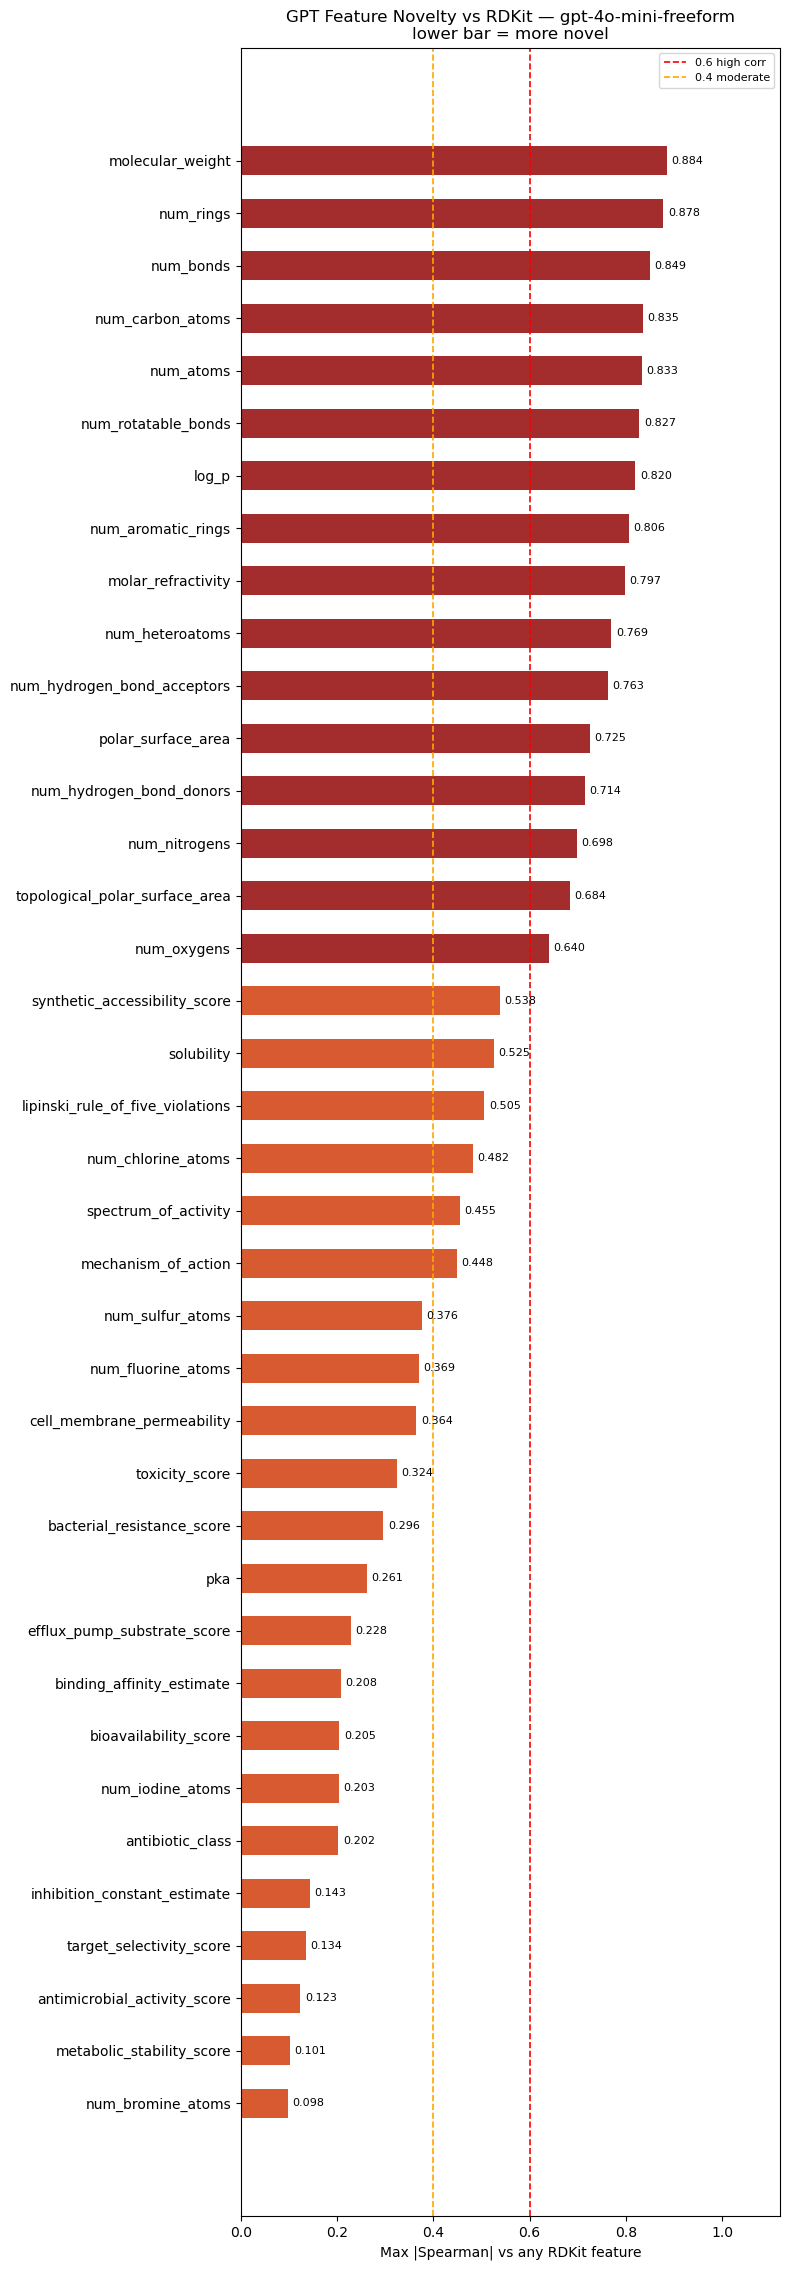

,gpt_feature,max_r_vs_rdkit,closest_rdkit
15,num_bromine_atoms,0.097744,HeavyAtomMolWt
29,metabolic_stability_score,0.101157,SMR_VSA1
26,antimicrobial_activity_score,0.122874,Chi0n
31,target_selectivity_score,0.134356,InertialShapeFactor
34,inhibition_constant_estimate,0.143342,MolLogP
35,antibiotic_class,0.201713,NumHeteroatoms
16,num_iodine_atoms,0.202938,SMR_VSA10
25,bioavailability_score,0.204893,SMR_VSA1
30,binding_affinity_estimate,0.207909,MolMR
33,efflux_pump_substrate_score,0.228001,Kappa1


In [9]:
rdkit_cols_list = [c for c in corr_sp.columns if c.startswith("rdkit__")]
gpt_cols_list   = [c for c in corr_sp.columns if c.startswith("gpt__")]

novelty = []
for g in gpt_cols_list:
    row = corr_sp.loc[g, rdkit_cols_list].abs()
    novelty.append({"gpt_feature": g.replace("gpt__", ""),
                    "max_r_vs_rdkit": float(row.max()),
                    "closest_rdkit": row.idxmax().replace("rdkit__", "")})

nov_df = pd.DataFrame(novelty).sort_values("max_r_vs_rdkit", ascending=True)

fig, ax = plt.subplots(figsize=(8, max(3, len(nov_df) * 0.6)))
colors  = ["#A32D2D" if r > 0.6 else "#D85A30" for r in nov_df["max_r_vs_rdkit"]]
bars    = ax.barh(nov_df["gpt_feature"], nov_df["max_r_vs_rdkit"], color=colors, height=0.55)
ax.axvline(0.6, color="red",    linestyle="--", lw=1.2, label="0.6 high corr")
ax.axvline(0.4, color="orange", linestyle="--", lw=1.2, label="0.4 moderate")
for bar, val in zip(bars, nov_df["max_r_vs_rdkit"]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=8)
ax.set_xlabel("Max |Spearman| vs any RDKit feature")
ax.set_title(f"GPT Feature Novelty vs RDKit — {MODEL_TAG}\nlower bar = more novel")
ax.legend(fontsize=8)
ax.set_xlim(0, 1.12)
plt.tight_layout()
plt.savefig(OUT_DIR / "novelty_bar.png", dpi=150, bbox_inches="tight")
plt.show()
nov_df

## 4. Build Feature Matrix

In [10]:
feat_df = raw[["prestwick_ID"] + feature_cols].copy()
for col in feature_cols:
    feat_df[col] = pd.to_numeric(feat_df[col], errors="coerce").fillna(0)

keep    = [c for c in feature_cols if feat_df[c].std() > 1e-6]
dropped = [c for c in feature_cols if c not in keep]
if dropped:
    print(f"Dropped zero-variance: {dropped}")
feat_df = feat_df[["prestwick_ID"] + keep]
print(f"Feature matrix: {feat_df.shape}  ({len(feature_cols)} -> {len(keep)} features)")

Feature matrix: (1197, 39)  (38 -> 38 features)


In [11]:
pairs = pd.read_csv(PAIRS_FILE, usecols=["prestwick_ID", "bacterium", "label", "split"])
print(f"Pairs: {pairs.shape}  |  label dist: {pairs['label'].value_counts().to_dict()}")

df = pairs.merge(feat_df, on="prestwick_ID", how="inner")
missing = set(pairs["prestwick_ID"]) - set(feat_df["prestwick_ID"])
print(f"After merge: {df.shape}  |  unmatched compounds: {len(missing)}")

Pairs: (47880, 4)  |  label dist: {0: 41338, 1: 6542}
After merge: (47880, 42)  |  unmatched compounds: 0
